# Nested Clustered Optimization under Estimation Error

Public observations cannot reveal their exact population covariance or provide independent repeated histories. This notebook therefore shows every step used to generate controlled data for questions that require known truth, and it later uses the fixed public archive for the chronological comparison. Repeated generated samples measure how far estimated weights move from the weights obtained from the known population inputs:

$$
E_m^{(b)}=\left[\frac{1}{N}\sum_{i=1}^{N}\left(\widehat w_{m,i}^{(b)}-w_{m,i}^{0}\right)^2\right]^{1/2}.
$$

Here, $m$ labels an allocation method, $b$ labels an independent repetition, $N$ is the number of assets, $\widehat w_{m,i}^{(b)}$ is the estimated weight of asset $i$, $w_{m,i}^{0}$ is the weight from the known population inputs, and $E_m^{(b)}$ is the allocation root mean squared error.

Row,Quantity,Value
,String,Float64
1,Assets,24.0
2,Blocks,4.0
3,Assets per block,6.0
4,Within-block correlation,0.55
5,Between-block correlation,0.04
6,Training observations,180.0
7,Repeated samples per objective,40.0
8,Random-state base,2202.0


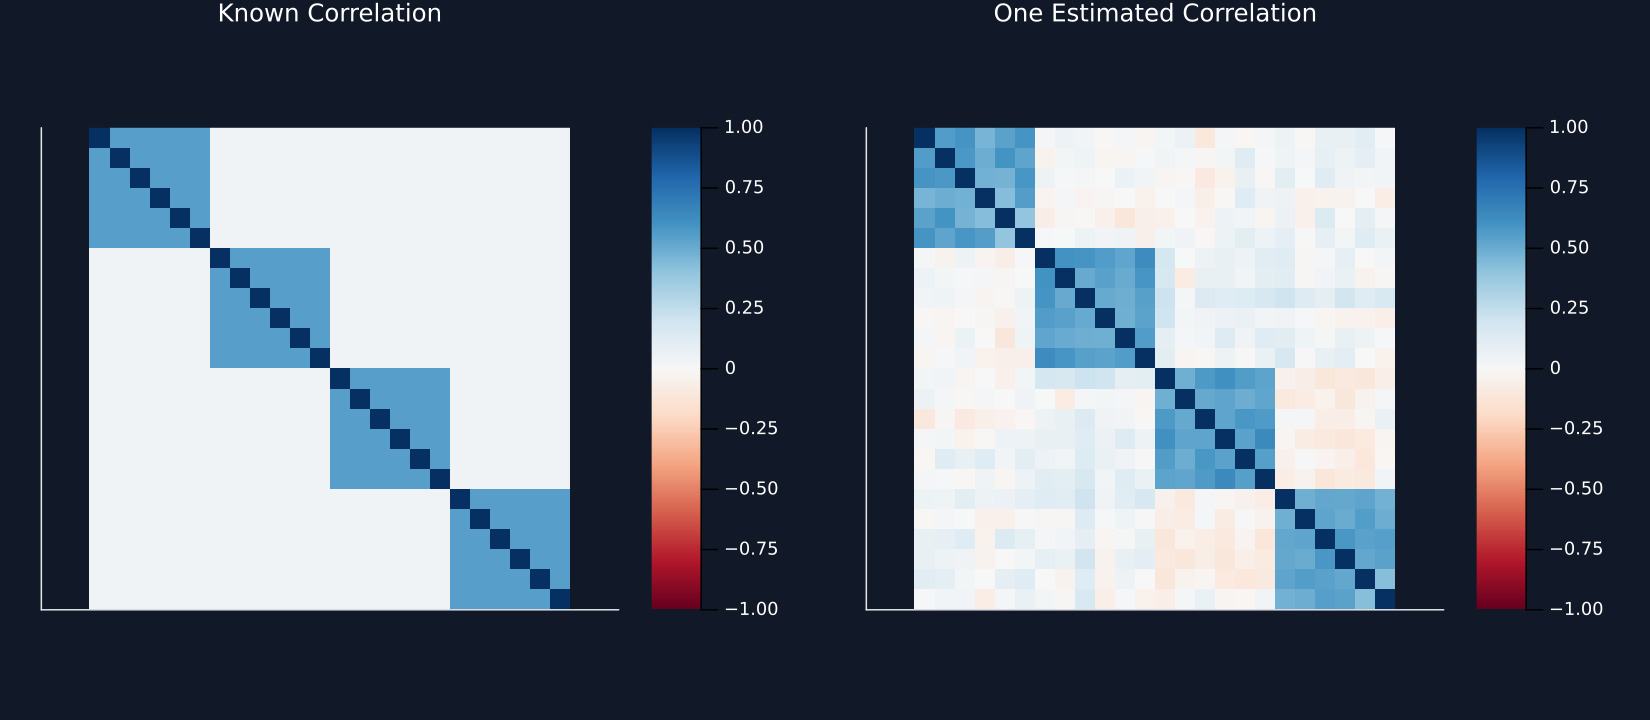

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots, CSV, TOML, Printf
include(joinpath("..", "support", "BookSupport.jl"))
include(joinpath("..", "support", "BookNCO.jl"))
include(joinpath("..", "support", "BookHierarchy.jl"))
using .BookSupport, .BookNCO, .BookHierarchy
import .BookSupport: palette
using RiskLabAI.Optimization: get_optimal_portfolio_weights, get_optimal_portfolio_weights_nco, hrp, inverse_variance_weights
using RiskLabAI.Data: denoise_cov, cov_to_corr, pca, find_max_eval
using RiskLabAI.ParallelWork: parallel_run
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("26_nested_cluster_optimization")
violet = "#C084FC"
data_path = dataset_path("french_49_industries")
@assert isfile(data_path)
public_lines = readlines(data_path)
first_row = findfirst(startswith(",Agric"), public_lines)
last_row = findnext(line -> isempty(strip(line)), public_lines, first_row + 1)
raw = CSV.read(IOBuffer(join(public_lines[first_row:last_row-1], "\n")), DataFrame)
all_dates = Date.(string.(raw[!, 1]), dateformat"yyyymmdd")
all_values = Matrix{Float64}(raw[:, 2:end])
valid = (Date(2019, 1, 1) .<= all_dates) .& (all_dates .<= Date(2025, 12, 31)) .& vec(all((all_values .!= -99.99) .& (all_values .!= -999.0); dims=2))
dates = all_dates[valid]
public_sample = all_values[valid, 1:16] ./ 100
selected_assets = ["Agriculture", "Food products", "Soft drinks", "Beer and liquor", "Tobacco", "Recreation", "Entertainment", "Printing and publishing", "Household products", "Apparel", "Health care", "Medical equipment", "Pharmaceutical products", "Chemicals", "Rubber and plastic products", "Textiles"]
random_root = joinpath("..", "data", "chapter26_random_inputs")
random_manifest = TOML.parsefile(joinpath(random_root, "inputs.toml"))["files"]
function primitive(name)
    path = joinpath(random_root, name)
    return Matrix{Float64}(CSV.read(path, DataFrame))
end
convention_path = joinpath(random_root, "coordinate_convention.toml")
coordinate_conventions = TOML.parsefile(convention_path)["families"]
publish(frame, name, caption, label; digits=6) = save_table(frame, paths, name; caption, label, digits)
candidate_rows, cluster_rows, weight_rows, sample_rows, covariance_rows = NamedTuple[], NamedTuple[], NamedTuple[], NamedTuple[], NamedTuple[]
case_order = String[]
function record_weights(case, method, weights)
    append!(weight_rows, [(case=case, method=method, asset=i, weight=weights[i]) for i in eachindex(weights)])
    return weights
end
function fitted_nco(case, covariance, seed; mu=nothing)
    push!(case_order, case)
    batch = length(case_order)
    draws = primitive("kmeans_" * string(seed) * ".csv")
    trace = function(step, k, features, fitted)
        append!(candidate_rows, [(case=case, batch=batch, step=step, clusters=k, seed=Int(draws[step, 1]), asset=i, label=fitted.labels[i], inertia=fitted.inertia, iterations=fitted.iterations) for i in eachindex(fitted.labels)])
    end
    result = BookNCO.nco_components(covariance, draws; mu, trace)
    labels = zeros(Int, size(covariance, 1))
    for (label, members) in result.clusters
        labels[members] .= label
    end
    append!(cluster_rows, [(case=case, batch=batch, asset=i, label=labels[i], silhouette=result.silhouette[i]) for i in eachindex(labels)])
    append!(covariance_rows, [(case=case, row=i, column=j, value=covariance[i, j]) for i in axes(covariance, 1) for j in axes(covariance, 2)])
    @assert maximum(abs.(result.final .- result.released)) < 1e-12
    record_weights(case, "NCO", result.final)
    return result.final
end
function experiment_sample(case, mean_return, covariance, within, filename)
    orientation = coordinate_conventions[string(round(Int, within * 100))]["orientation"]
    values = generator_samples(covariance, primitive(filename), orientation) .+ mean_return'
    append!(sample_rows, [(case=case, row=i, column=j, value=values[i, j]) for i in axes(values, 1) for j in axes(values, 2)])
    return values
end
portfolio_variance(weights, covariance) = dot(weights, covariance * weights)
optimal_weights(covariance, mean_return=nothing) = get_optimal_portfolio_weights(covariance; mu=mean_return)
function five_portfolios(case, covariance, seed)
    return ["Equal weight" => record_weights(case, "Equal weight", fill(1 / size(covariance, 1), size(covariance, 1))), "Inverse variance" => record_weights(case, "Inverse variance", inverse_variance_weights(covariance)), "HRP" => record_weights(case, "HRP", hrp(covariance, RiskLabAI.Cluster.covariance_to_correlation(covariance))), "Ordinary minimum variance" => record_weights(case, "Ordinary minimum variance", optimal_weights(covariance)), "NCO" => fitted_nco(case, covariance, seed)]
end
finite_mean(values) = mean(filter(isfinite, values))
public_allclose(a, b; rtol=1e-5, atol=1e-8) = all((a .== b) .| (isfinite.(b) .& (abs.(a .- b) .<= atol .+ rtol .* abs.(b))))
function draw_box!(figure, position, values, color)
    q1, median_value, q3 = quantile(values, [.25, .5, .75])
    spread = q3 - q1
    lower = minimum(filter(>=(q1 - 1.5spread), values))
    upper = maximum(filter(<=(q3 + 1.5spread), values))
    plot!(figure, Shape([position-.28, position+.28, position+.28, position-.28], [q1, q1, q3, q3]); color, fillalpha=.8, linecolor=palette.text, label=false)
    plot!(figure, [position-.28, position+.28], [median_value, median_value]; color=palette.text, label=false)
    plot!(figure, [position, position], [lower, q1]; color=palette.text, label=false)
    plot!(figure, [position, position], [q3, upper]; color=palette.text, label=false)
    for height in [lower, upper]
        plot!(figure, [position-.12, position+.12], [height, height]; color=palette.text, label=false)
    end
    return figure
end
true_covariance, true_correlation = block_covariance(4, 6, .55, .04)
true_mean = .055 .+ .012sin.(collect(0:23) .* ((2pi) / 24))
demonstration_returns = experiment_sample("demonstration", true_mean, true_covariance, .55, "demonstration_normals.csv")
demonstration_covariance, demonstration_correlation = cov(demonstration_returns), cor(demonstration_returns)
known_truth_design = DataFrame("Quantity" => ["Assets", "Blocks", "Assets per block", "Within-block correlation", "Between-block correlation", "Training observations", "Repeated samples per objective", "Random-state base"], "Value" => [24., 4., 6., .55, .04, 180., 40., 2202.])
publish(known_truth_design, "known_truth_nco_design", "Known-input repeated-sample design for Section 22.2.", "tab:chapter22-known-truth-design")
p1 = heatmap(true_correlation; color=:RdBu, clims=(-1, 1), title="Known Correlation", xticks=false, yticks=false, yflip=true, aspect_ratio=:equal)
p2 = heatmap(demonstration_correlation; color=:RdBu, clims=(-1, 1), title="One Estimated Correlation", xticks=false, yticks=false, yflip=true, aspect_ratio=:equal)
save_figure(plot(p1, p2; layout=(1, 2), size=(1100, 480)), paths, "known_and_estimated_nco_correlation")
save_data(DataFrame(true_covariance, :auto), paths, "true_covariance")
save_data(DataFrame(true_correlation, :auto), paths, "true_correlation")
save_data(DataFrame(demonstration_covariance, :auto), paths, "demonstration_covariance")
save_data(DataFrame(demonstration_correlation, :auto), paths, "demonstration_correlation")
nothing


## Comparing two portfolio objectives

The two unconstrained fully invested directions used in the repeated study differ only in the vector multiplied by the inverse covariance:

$$
w_{\mathrm{MV}}=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
w_{\mathrm{MS}}=\frac{\Sigma^{-1}\mu}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mu}.
$$

Here, $\Sigma$ is the covariance matrix, $\mu$ is the expected-return vector, $\mathbf 1$ is a vector of ones, $w_{\mathrm{MV}}$ is the minimum-variance portfolio, and $w_{\mathrm{MS}}$ is the normalized maximum-Sharpe direction when the cash rate is zero.

Row,Objective,Method,Mean own-decision error,Mean error to ordinary population optimum,Mean true variance,Mean true Sharpe ratio
,String,String,Float64,Float64,Float64,Float64
1,Maximum Sharpe,NCO,0.0459878,0.0463216,0.00460873,0.888663
2,Maximum Sharpe,Ordinary optimization,0.0666618,0.0666618,0.00530848,0.836249
3,Minimum variance,NCO,0.0220738,0.0222643,0.00398683,0.912922
4,Minimum variance,Ordinary optimization,0.0415362,0.0415362,0.00430348,0.878865


Row,Objective,NCO error as percent of ordinary error
,String,Float64
1,Maximum Sharpe,68.9866
2,Minimum variance,53.1434


Row,Objective,Securities,Blocks,Observations,Repetitions,Raw NCO error as percent of ordinary error,Source
,String,Int64,Int64,Int64,Int64,Float64,String
1,Minimum variance,50,10,1000,1000,44.95,Original 2019 NCO paper
2,Maximum Sharpe,50,10,1000,1000,42.2,Original 2019 NCO paper


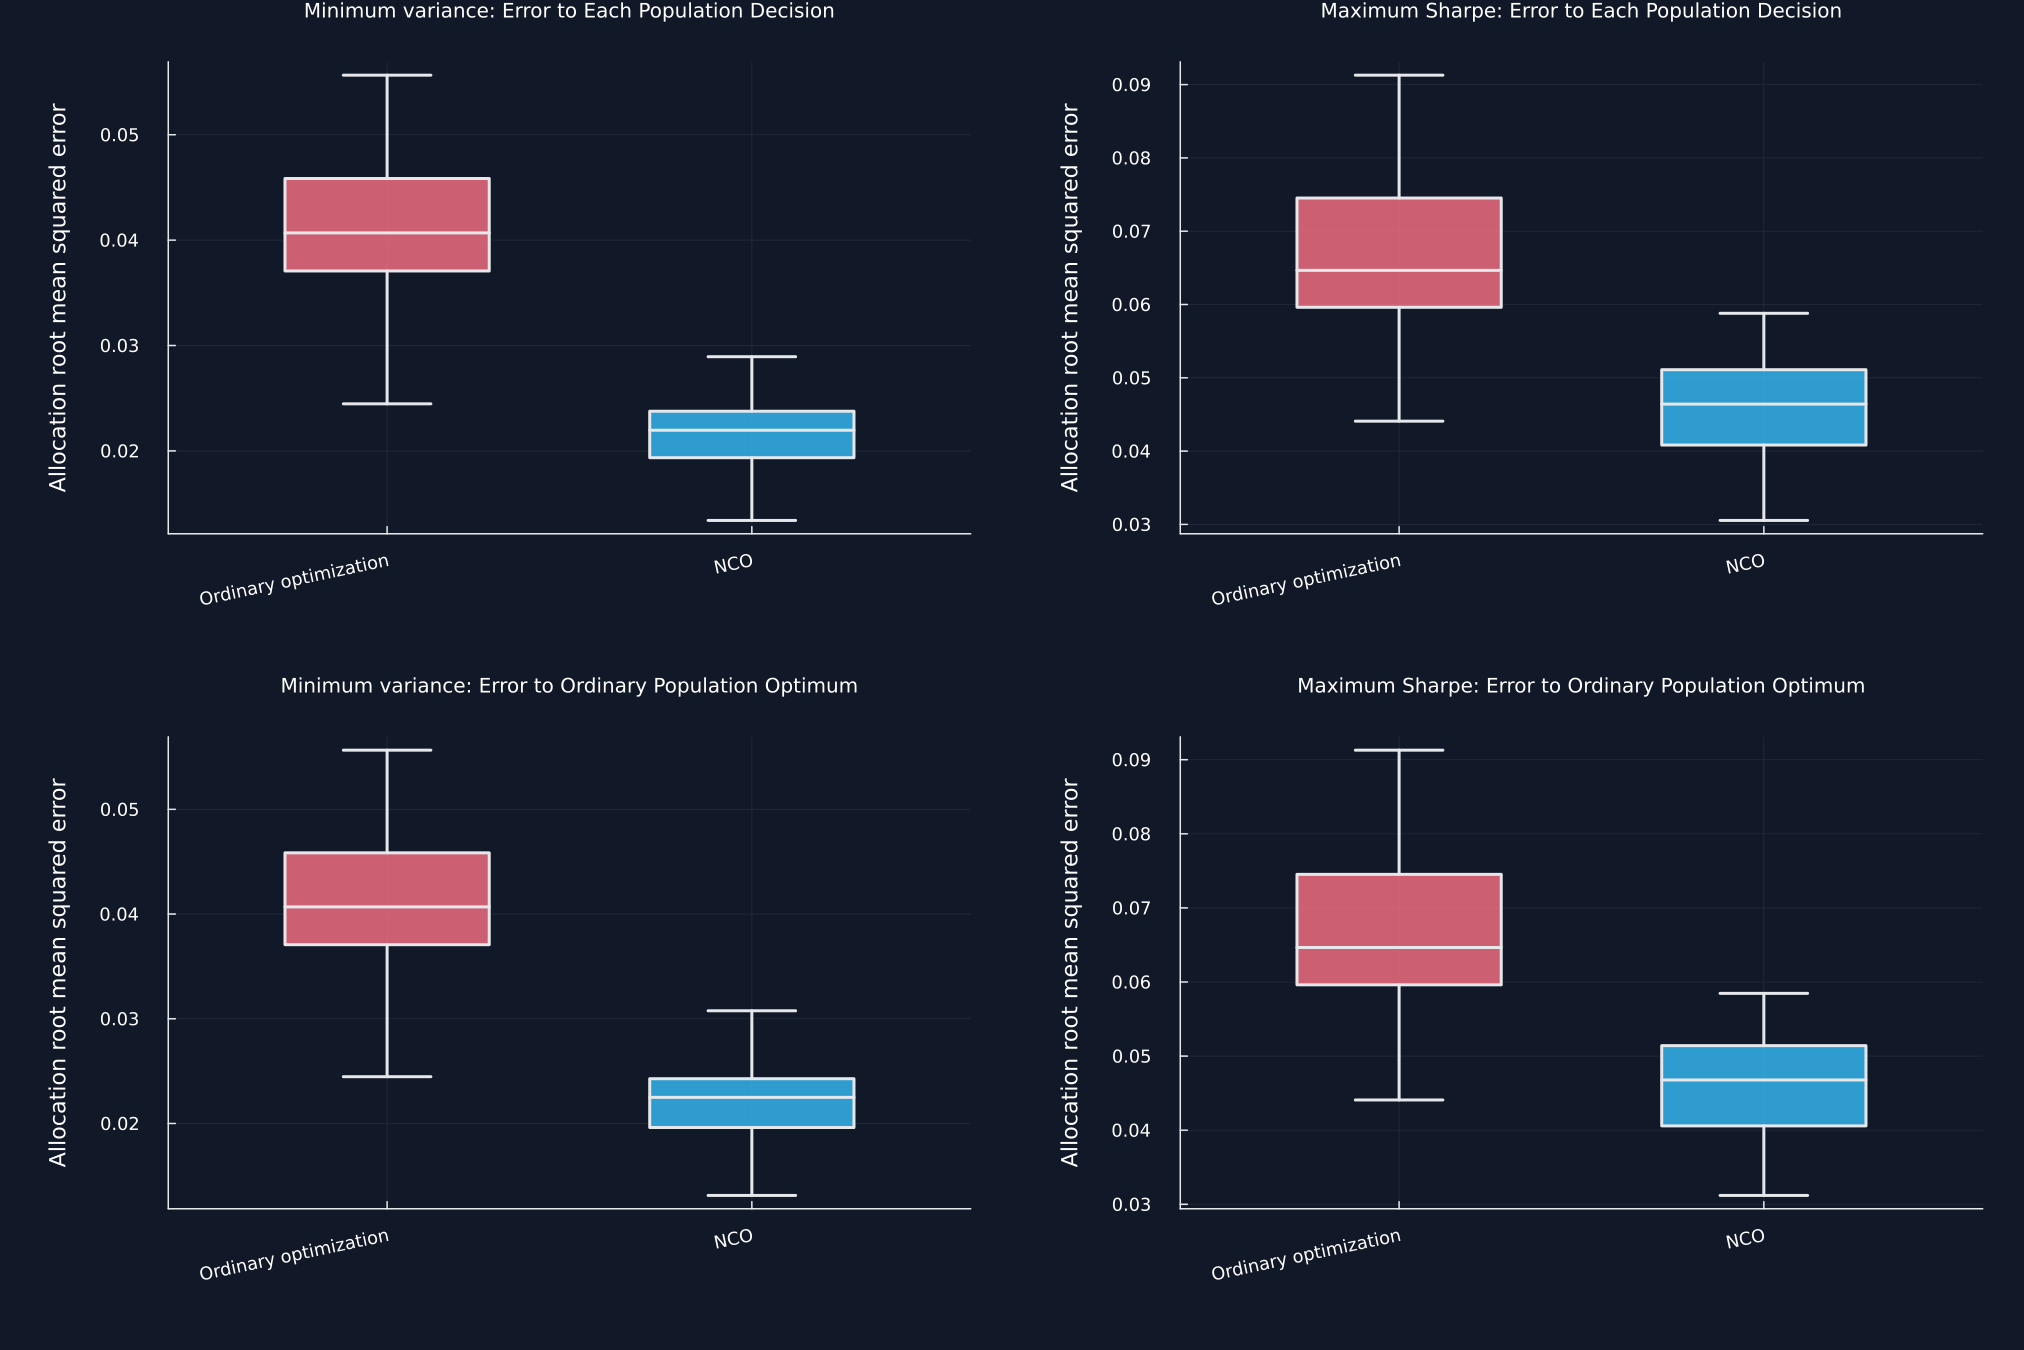

In [2]:
objective_specs = [("Minimum variance", nothing), ("Maximum Sharpe", true_mean)]
oracle_weights = Dict{Tuple{String,String},Vector{Float64}}()
for (objective_number, (objective_name, objective_mean)) in enumerate(objective_specs)
    case = "oracle_" * string(objective_number - 1)
    oracle_weights[(objective_name, "Ordinary optimization")] = record_weights(case, "Ordinary optimization", optimal_weights(true_covariance, objective_mean))
    oracle_weights[(objective_name, "NCO")] = fitted_nco(case, true_covariance, 2210; mu=objective_mean)
end
repeated_rows = NamedTuple[]
for (objective_number, (objective_name, objective_mean)) in enumerate(objective_specs)
    ordinary_oracle = oracle_weights[(objective_name, "Ordinary optimization")]
    for repetition in 1:40
        case = "repeated_" * string(objective_number - 1) * "_" * string(repetition)
        sample = experiment_sample(case, true_mean, true_covariance, .55, case * ".csv")
        sample_covariance = cov(sample)
        sample_mean = isnothing(objective_mean) ? nothing : vec(mean(sample; dims=1))
        fitted = ["Ordinary optimization" => record_weights(case, "Ordinary optimization", optimal_weights(sample_covariance, sample_mean)), "NCO" => fitted_nco(case, sample_covariance, 2210; mu=sample_mean)]
        for (method, weights) in fitted
            oracle = oracle_weights[(objective_name, method)]
            variance = portfolio_variance(weights, true_covariance)
            sharpe = dot(weights, true_mean) / sqrt(variance)
            push!(repeated_rows, (objective=objective_name, repetition=repetition, method=method, own=sqrt(mean((weights .- oracle).^2)), ordinary=sqrt(mean((weights .- ordinary_oracle).^2)), variance=variance, sharpe=sharpe, gross=sum(abs, weights), concentration=dot(weights, weights)))
        end
    end
end
mcos_results = DataFrame(repeated_rows)
rename!(mcos_results, ["Objective", "Repetition", "Method", "Own-decision allocation error", "Error to ordinary population optimum", "True variance", "True Sharpe ratio", "Gross exposure", "Weight concentration"])
mcos_summary = combine(groupby(mcos_results, ["Objective", "Method"]; sort=true), "Own-decision allocation error" => mean => "Mean own-decision error", "Own-decision allocation error" => median => "Median own-decision error", "Own-decision allocation error" => (values -> std(values) / sqrt(length(values))) => "Own-decision error standard error", "Error to ordinary population optimum" => mean => "Mean error to ordinary population optimum", "True variance" => mean => "Mean true variance", "True Sharpe ratio" => mean => "Mean true Sharpe ratio", "Gross exposure" => mean => "Mean gross exposure", "Weight concentration" => mean => "Mean weight concentration")
error_rows = NamedTuple[]
for objective_name in sort(first.(objective_specs))
    subset = mcos_summary[mcos_summary.Objective .== objective_name, :]
    ratio = 100 * only(subset[subset.Method .== "NCO", "Mean own-decision error"]) / only(subset[subset.Method .== "Ordinary optimization", "Mean own-decision error"])
    push!(error_rows, (objective=objective_name, ratio=ratio))
end
error_ratios = DataFrame(error_rows)
rename!(error_ratios, ["Objective", "NCO error as percent of ordinary error"])
paper_design_results = DataFrame("Objective" => ["Minimum variance", "Maximum Sharpe"], "Securities" => [50, 50], "Blocks" => [10, 10], "Observations" => [1000, 1000], "Repetitions" => [1000, 1000], "Raw NCO error as percent of ordinary error" => [44.95, 42.20], "Source" => fill("Original 2019 NCO paper", 2))
mcos_book_summary = mcos_summary[:, ["Objective", "Method", "Mean own-decision error", "Mean error to ordinary population optimum", "Mean true variance", "Mean true Sharpe ratio"]]
publish(mcos_book_summary, "mcos_nco_summary", "Repeated allocation error and known-input performance summaries.", "tab:chapter22-mcos-summary")
publish(error_ratios, "mcos_nco_error_ratios", "NCO allocation error relative to ordinary optimization in the Chapter 22 calculation.", "tab:chapter22-mcos-ratios")
publish(paper_design_results, "original_nco_paper_results", "Design-limited allocation-error ratios reported in the original NCO paper.", "tab:chapter22-original-paper-results")
panels = Any[]
for (measure, row_title) in [("Own-decision allocation error", "Error to Each Population Decision"), ("Error to ordinary population optimum", "Error to Ordinary Population Optimum")]
    for objective_name in ["Minimum variance", "Maximum Sharpe"]
        figure = plot(; title=objective_name * ": " * row_title, titlefontsize=9, ylabel="Allocation root mean squared error", xticks=([1, 2], ["Ordinary optimization", "NCO"]), xrotation=12, xlims=(.4, 2.6), legend=false)
        for (index, method, color) in [(1, "Ordinary optimization", palette.rose), (2, "NCO", palette.cyan)]
            values = mcos_results[(mcos_results.Objective .== objective_name) .& (mcos_results.Method .== method), measure]
            draw_box!(figure, index, values, color)
        end
        push!(panels, figure)
    end
end
save_figure(plot(panels...; layout=(2, 2), size=(1350, 900), bottom_margin=12Plots.mm, left_margin=12Plots.mm), paths, "mcos_allocation_error")
save_data(mcos_results, paths, "mcos_results")
save_data(mcos_summary, paths, "mcos_summary")
nothing


## Comparing five portfolio rules after covariance cleaning

The observations-per-asset ratio records the amount of covariance information available for each dimension:

$$
\eta=\frac{T}{N}.
$$

Here, $T$ is the number of observations, $N$ is the number of assets, and $\eta$ is smaller when covariance estimation is more difficult.

Row,Covariance input,Method,Known true variance,Gross exposure,Weight concentration,Largest absolute weight
,String,String,Float64,Float64,Float64,Float64
1,Raw sample covariance,Equal weight,0.00494864,1.0,0.0416667,0.0416667
2,Raw sample covariance,Inverse variance,0.00399329,1.0,0.0532082,0.0857822
3,Raw sample covariance,HRP,0.00408097,1.0,0.0569732,0.115628
4,Raw sample covariance,Ordinary minimum variance,0.00436148,1.18643,0.10269,0.182026
5,Raw sample covariance,NCO,0.00403652,1.07786,0.0776196,0.143114
6,Denoised sample covariance,Equal weight,0.00494864,1.0,0.0416667,0.0416667
7,Denoised sample covariance,Inverse variance,0.00399329,1.0,0.0532082,0.0857822
8,Denoised sample covariance,HRP,0.00401607,1.0,0.0573374,0.107968
9,Denoised sample covariance,Ordinary minimum variance,0.00422771,1.15906,0.0909895,0.149516


Row,Method,Raw known variance,Denoised known variance,Denoised-to-raw variance ratio
,String,Float64,Float64,Float64
1,Equal weight,0.00494864,0.00494864,1.0
2,HRP,0.00408097,0.00401607,0.984095
3,Inverse variance,0.00399329,0.00399329,1.0
4,NCO,0.00403652,0.0039693,0.983347
5,Ordinary minimum variance,0.00436148,0.00422771,0.96933


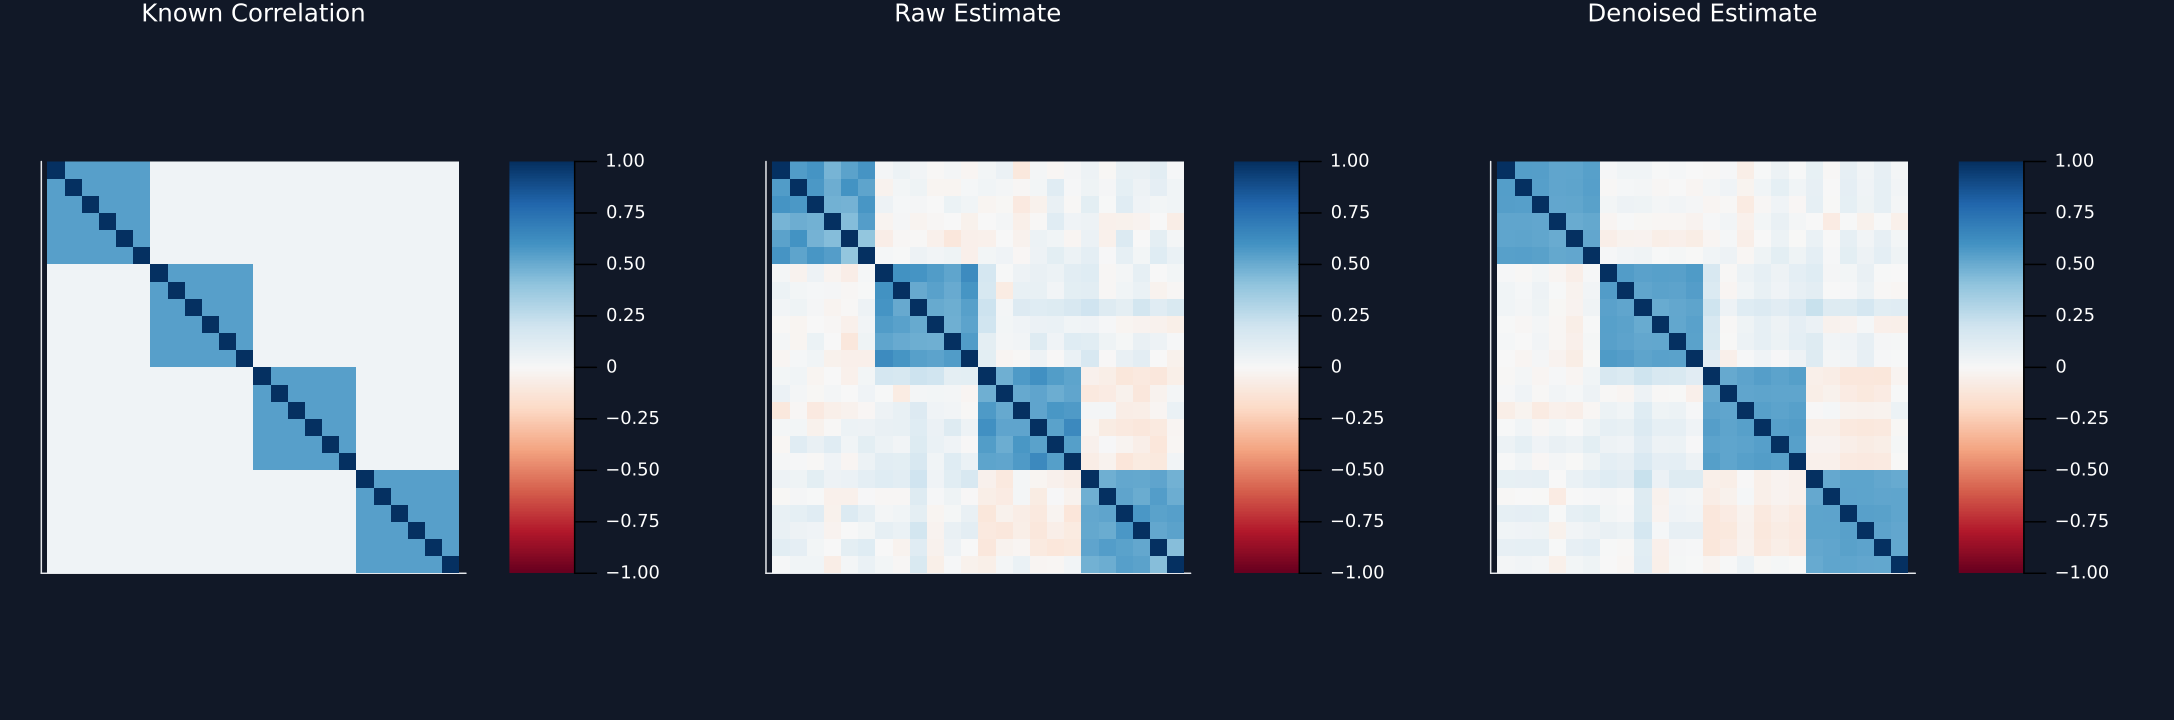

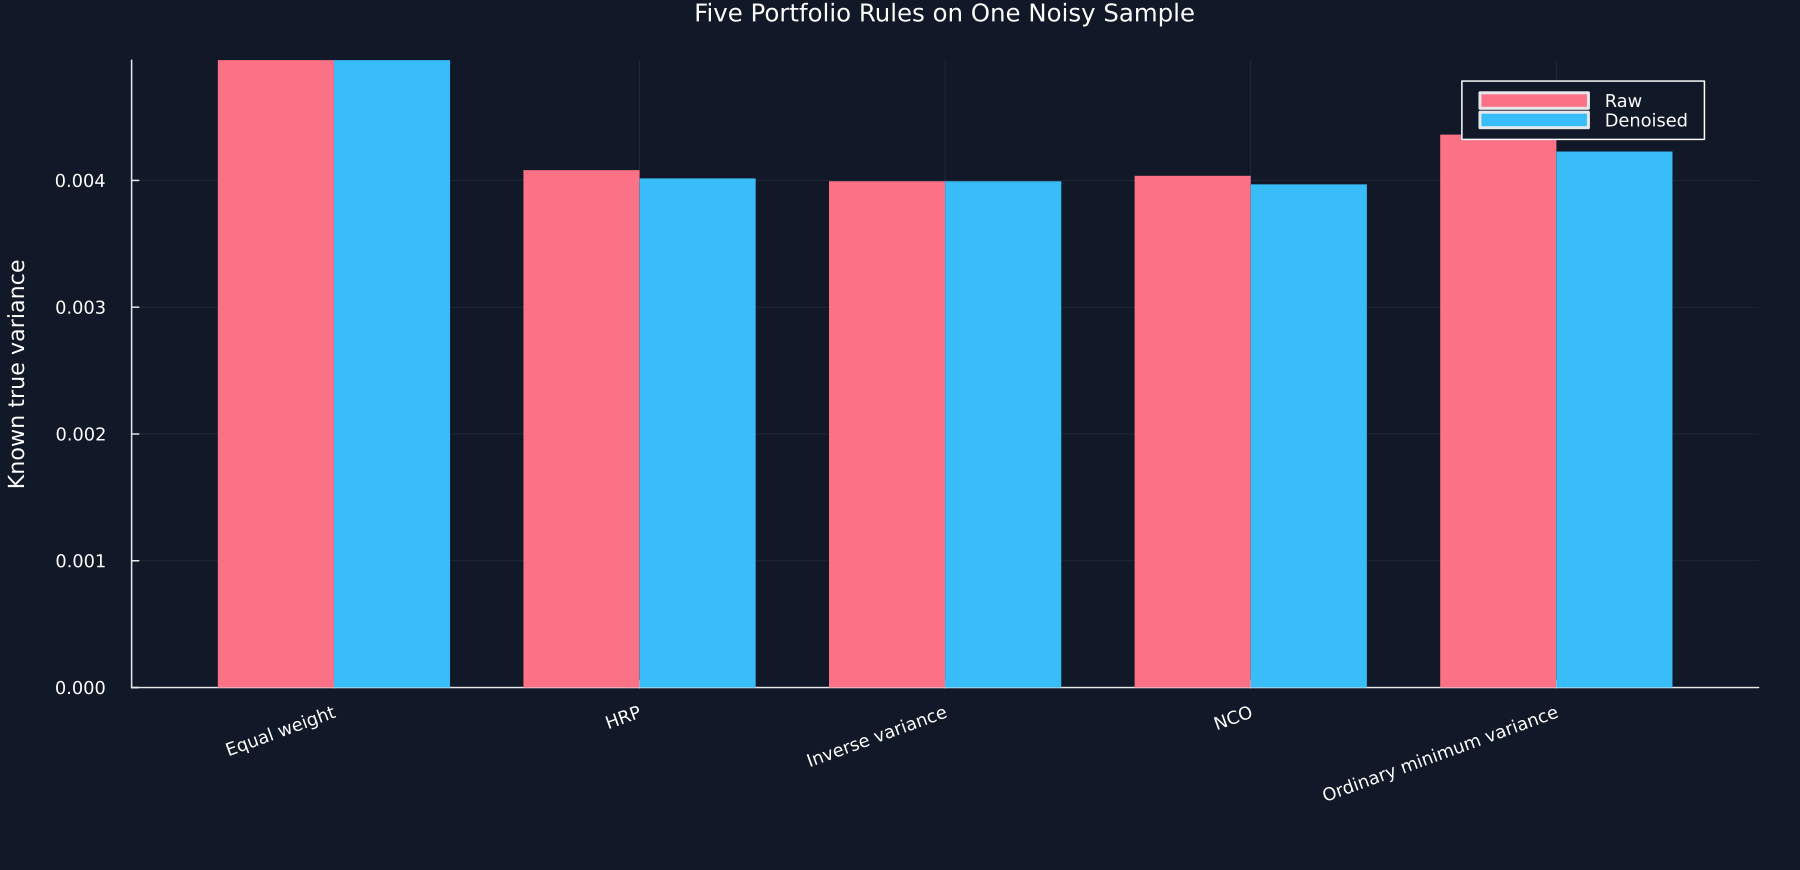

In [3]:
demonstration_denoised = denoise_cov(demonstration_covariance, 180 / 24; bandwidth=.01)
raw_portfolios = five_portfolios("demo_raw", demonstration_covariance, 2220)
denoised_portfolios = five_portfolios("demo_denoised", demonstration_denoised, 2220)
denoising_rows = NamedTuple[]
for (covariance_name, portfolios) in [("Raw sample covariance", raw_portfolios), ("Denoised sample covariance", denoised_portfolios)]
    for (method, weights) in portfolios
        push!(denoising_rows, (input=covariance_name, method=method, variance=portfolio_variance(weights, true_covariance), gross=sum(abs, weights), concentration=dot(weights, weights), largest=maximum(abs, weights)))
    end
end
denoising_summary = DataFrame(denoising_rows)
rename!(denoising_summary, ["Covariance input", "Method", "Known true variance", "Gross exposure", "Weight concentration", "Largest absolute weight"])
comparison_rows = NamedTuple[]
for method in sort(first.(raw_portfolios))
    subset = denoising_summary[denoising_summary.Method .== method, :]
    raw_variance = only(subset[subset[!, "Covariance input"] .== "Raw sample covariance", "Known true variance"])
    cleaned_variance = only(subset[subset[!, "Covariance input"] .== "Denoised sample covariance", "Known true variance"])
    push!(comparison_rows, (method=method, raw=raw_variance, cleaned=cleaned_variance, ratio=cleaned_variance / raw_variance))
end
denoising_comparison = DataFrame(comparison_rows)
rename!(denoising_comparison, ["Method", "Raw known variance", "Denoised known variance", "Denoised-to-raw variance ratio"])
publish(denoising_summary, "raw_denoised_portfolio_summary", "Known-input risk and weight diagnostics for raw and denoised covariance inputs.", "tab:chapter22-denoising-summary")
publish(denoising_comparison, "raw_denoised_variance_comparison", "Known true variance before and after covariance cleaning.", "tab:chapter22-denoising-comparison")
panels = [heatmap(matrix; color=:RdBu, clims=(-1, 1), title=title, xticks=false, yticks=false, yflip=true, aspect_ratio=:equal) for (matrix, title) in [(true_correlation, "Known Correlation"), (demonstration_correlation, "Raw Estimate"), (RiskLabAI.Cluster.covariance_to_correlation(demonstration_denoised), "Denoised Estimate")]]
save_figure(plot(panels...; layout=(1, 3), size=(1450, 480)), paths, "denoising_correlation_comparison")
positions = collect(1:nrow(denoising_comparison))
figure = bar(positions .- .19, denoising_comparison[!, "Raw known variance"]; bar_width=.38, color=palette.rose, linealpha=0, label="Raw", xticks=(positions, denoising_comparison.Method), xrotation=20, ylabel="Known true variance", title="Five Portfolio Rules on One Noisy Sample", size=(1200, 580), bottom_margin=18Plots.mm)
bar!(figure, positions .+ .19, denoising_comparison[!, "Denoised known variance"]; bar_width=.38, color=palette.cyan, linealpha=0, label="Denoised")
save_figure(figure, paths, "denoising_true_risk_comparison")
save_data(DataFrame(demonstration_denoised, :auto), paths, "demonstration_denoised")
eigenvalues, _ = pca(cov_to_corr(demonstration_covariance))
noise_cutoff, noise_variance = find_max_eval(eigenvalues, 180 / 24, .01)
save_data(DataFrame(cutoff=[noise_cutoff], variance=[noise_variance], factors=[count(>(noise_cutoff), eigenvalues)]), paths, "current_noise_fit")
nothing


## Testing nested optimization across sample regimes

True-risk inflation compares an estimated portfolio with the population minimum-variance benchmark:

$$
R_m^{(b)}=\frac{(\widehat w_m^{(b)})^{\mathsf T}\Sigma_0\widehat w_m^{(b)}}{(w_{\mathrm{MV}}^0)^{\mathsf T}\Sigma_0w_{\mathrm{MV}}^0}.
$$

Here, $\Sigma_0$ is the known covariance matrix, $\widehat w_m^{(b)}$ is the estimated weight vector for method $m$ in repetition $b$, $w_{\mathrm{MV}}^0$ is the population minimum-variance portfolio, and $R_m^{(b)}$ equals one at the population minimum. Each plotted mean uses ten repetitions. The shaded interval is the mean plus or minus $1.96$ estimated standard errors, so it describes simulation uncertainty in this small controlled study rather than a universal performance range.

Row,Within-cluster correlation,Observations per asset,Method,Mean true-risk ratio,True-risk standard error,Mean gross exposure
,Float64,Float64,String,Float64,Float64,Float64
1,0.3,3.33333,NCO,1.10755,0.0233057,1.04145
2,0.3,3.33333,Ordinary minimum variance,1.36669,0.0402971,1.27298
3,0.3,6.66667,NCO,1.06249,0.00874975,1.00463
4,0.3,6.66667,Ordinary minimum variance,1.1723,0.0187752,1.10791
5,0.3,13.3333,NCO,1.02443,0.00288542,1.0
6,0.3,13.3333,Ordinary minimum variance,1.08119,0.0116654,1.04748
7,0.6,3.33333,NCO,1.09716,0.016309,1.17144
8,0.6,3.33333,Ordinary minimum variance,1.43999,0.0292755,1.8715
9,0.6,6.66667,NCO,1.05398,0.00767194,1.14233


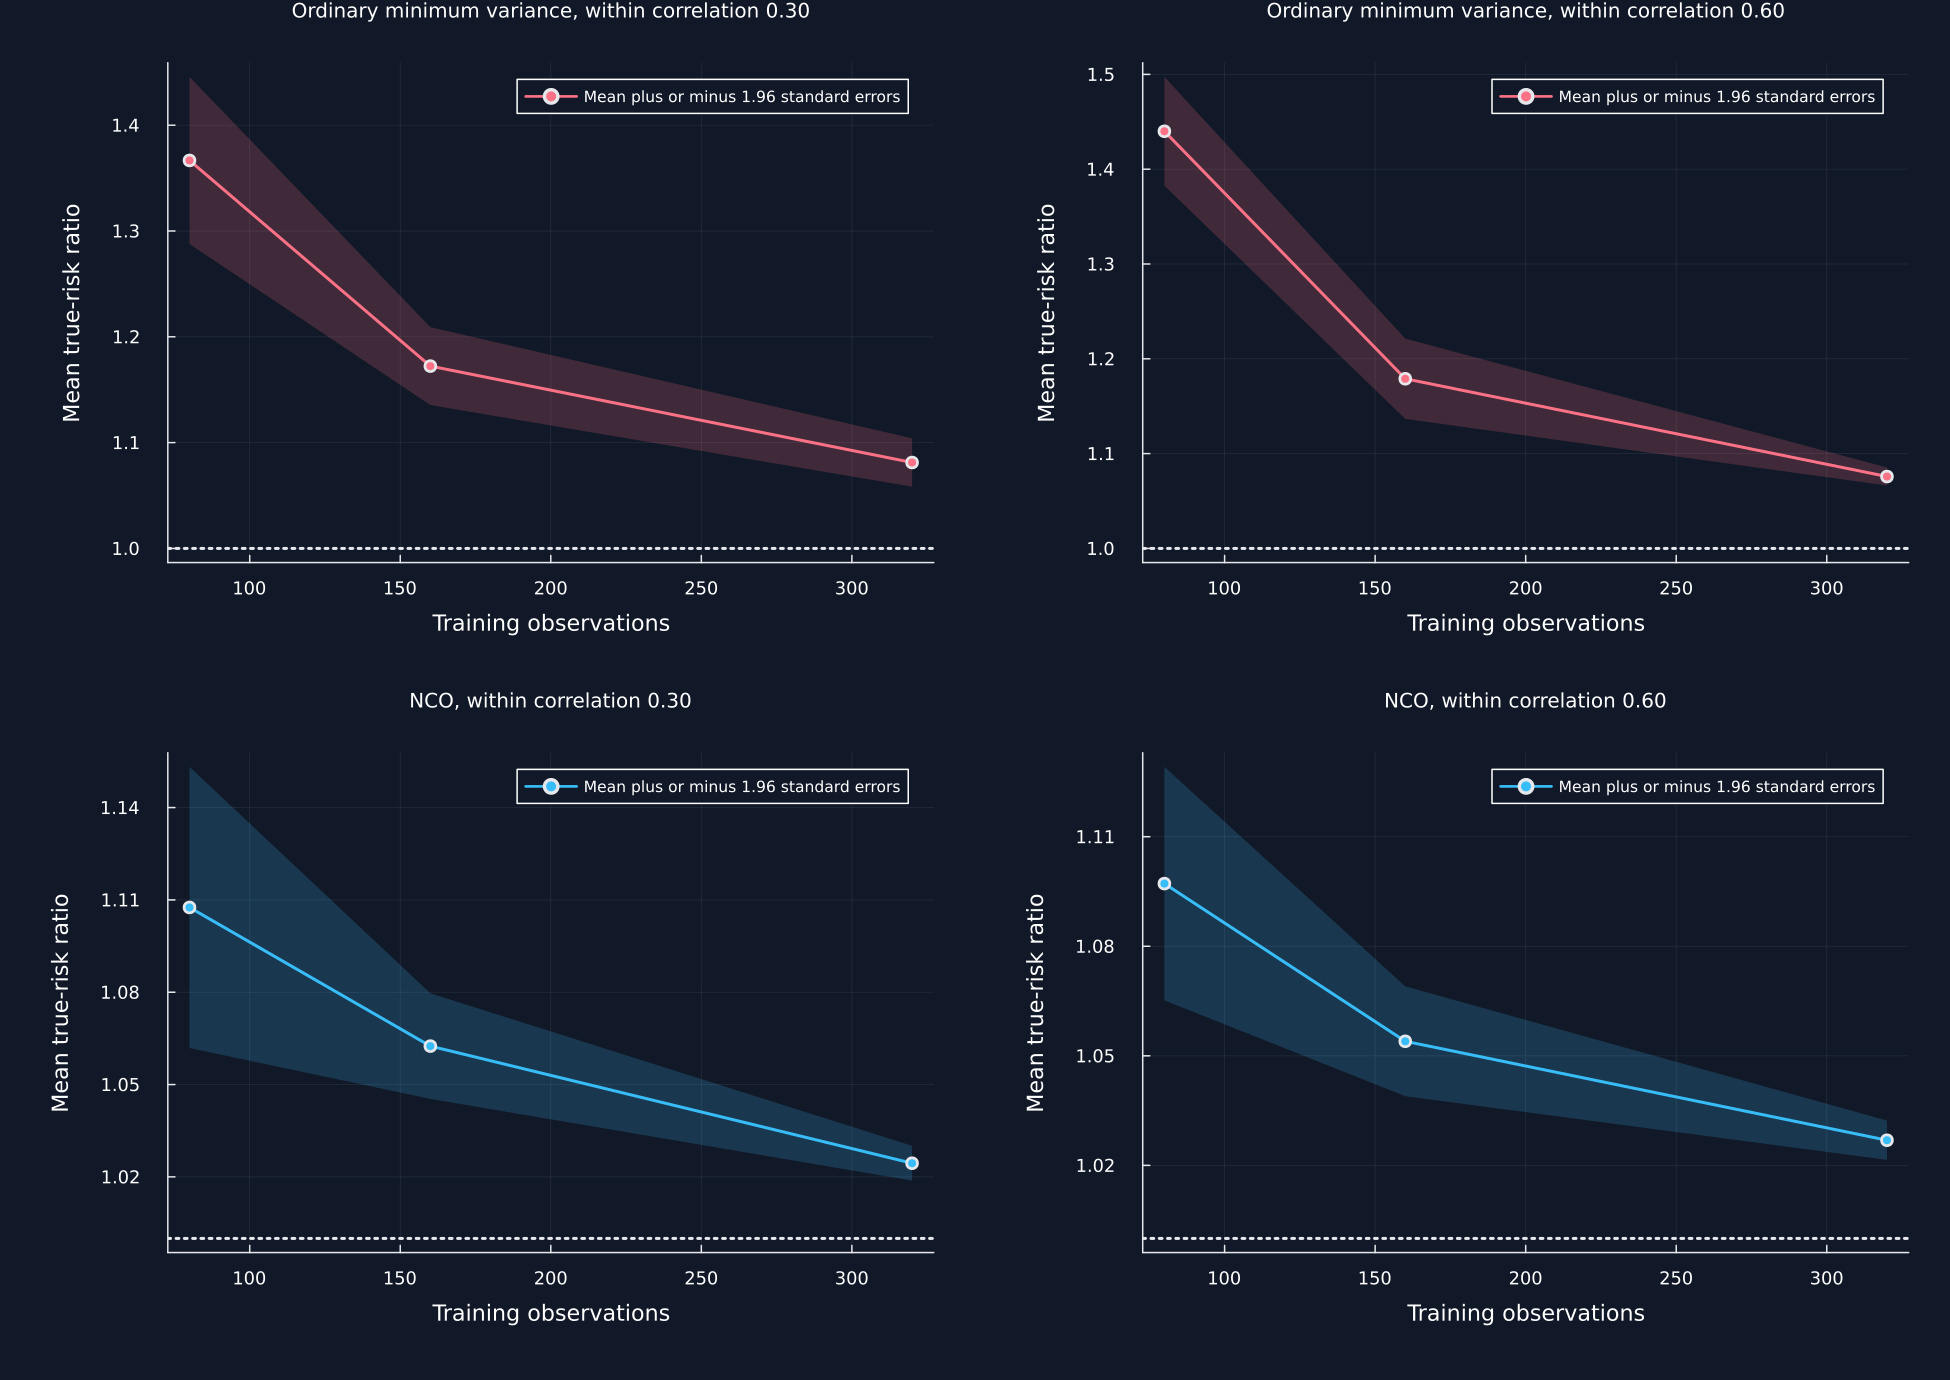

In [4]:
sensitivity_rows = NamedTuple[]
for within_correlation in [.30, .60]
    sensitivity_covariance, sensitivity_correlation = block_covariance(4, 6, within_correlation, .04)
    population_minimum = optimal_weights(sensitivity_covariance)
    population_variance = portfolio_variance(population_minimum, sensitivity_covariance)
    for training_observations in [80, 160, 320], repetition in 1:10
        case = "sensitivity_" * string(Int(within_correlation * 100)) * "_" * string(training_observations) * "_" * string(repetition)
        sample = experiment_sample(case, zeros(24), sensitivity_covariance, within_correlation, case * ".csv")
        sample_covariance = cov(sample)
        fitted = ["Ordinary minimum variance" => record_weights(case, "Ordinary minimum variance", optimal_weights(sample_covariance)), "NCO" => fitted_nco(case, sample_covariance, 2230)]
        for (method, weights) in fitted
            push!(sensitivity_rows, (within=within_correlation, training=training_observations, assets=24, ratio=training_observations / 24, repetition=repetition, method=method, risk=portfolio_variance(weights, sensitivity_covariance) / population_variance, gross=sum(abs, weights)))
        end
    end
end
sensitivity_results = DataFrame(sensitivity_rows)
rename!(sensitivity_results, ["Within-cluster correlation", "Training observations", "Assets", "Observations per asset", "Repetition", "Method", "True-risk ratio", "Gross exposure"])
sensitivity_summary = combine(groupby(sensitivity_results, ["Within-cluster correlation", "Training observations", "Assets", "Observations per asset", "Method"]; sort=true), "True-risk ratio" => mean => "Mean true-risk ratio", "True-risk ratio" => median => "Median true-risk ratio", "True-risk ratio" => (values -> std(values) / sqrt(length(values))) => "True-risk standard error", "Gross exposure" => mean => "Mean gross exposure")
sensitivity_book_summary = sensitivity_summary[:, ["Within-cluster correlation", "Observations per asset", "Method", "Mean true-risk ratio", "True-risk standard error", "Mean gross exposure"]]
publish(sensitivity_book_summary, "nco_sampling_sensitivity", "Known-covariance sensitivity to sample size and cluster strength.", "tab:chapter22-sensitivity")
panels = Any[]
for method in ["Ordinary minimum variance", "NCO"], within_correlation in [.30, .60]
    subset = sensitivity_summary[(sensitivity_summary.Method .== method) .& (sensitivity_summary[!, "Within-cluster correlation"] .== within_correlation), :]
    sort!(subset, "Training observations")
    color = startswith(method, "Ordinary") ? palette.rose : palette.cyan
    figure = plot(subset[!, "Training observations"], subset[!, "Mean true-risk ratio"]; ribbon=1.96 .* subset[!, "True-risk standard error"], fillalpha=.2, color, marker=:circle, label="Mean plus or minus 1.96 standard errors", legendfontsize=7, title=method * ", within correlation " * @sprintf("%.2f", within_correlation), titlefontsize=9, xlabel="Training observations", ylabel="Mean true-risk ratio")
    hline!(figure, [1.]; color=palette.text, linestyle=:dot, label=false)
    push!(panels, figure)
end
save_figure(plot(panels...; layout=(2, 2), size=(1300, 920), left_margin=12Plots.mm, bottom_margin=10Plots.mm), paths, "nco_sampling_sensitivity")
save_data(sensitivity_results, paths, "sensitivity_results")
save_data(sensitivity_summary, paths, "sensitivity_summary")
nothing


## A Conditional Bridge to Global Minimum Variance

Cotton's bridge changes both the covariance used inside each cluster and the direction that accompanies it before the final allocation across clusters:

$$
\begin{aligned}
Q_g(\gamma)&=\Sigma_{gg}-\gamma\Sigma_{g,P_{-g}}\Sigma_{P_{-g},P_{-g}}^{-1}\Sigma_{P_{-g},g},\\
b_g(\gamma)&=\mathbf 1_g-\gamma\Sigma_{g,P_{-g}}\Sigma_{P_{-g},P_{-g}}^{-1}\mathbf 1_{P_{-g}},\\
d_g(\gamma)&=Q_g(\gamma)^{-1}b_g(\gamma),\\
\widetilde w_\gamma&=D_\gamma(D_\gamma^{\mathsf T}\Sigma D_\gamma)^{-1}D_\gamma^{\mathsf T}\mathbf 1,
\qquad
w_\gamma=\frac{\widetilde w_\gamma}{\mathbf 1^{\mathsf T}\widetilde w_\gamma}.
\end{aligned}
$$

Here, $g$ labels a cluster, $P_{-g}$ contains one chosen representative, called a knot, from every other cluster, $\Sigma_{g,P_{-g}}$ is the covariance between cluster $g$ and those knots, $\mathbf 1_g$ and $\mathbf 1_{P_{-g}}$ are vectors of ones of the required sizes, and $0\leq\gamma\leq1$ controls how much outside information is used. The matrix $Q_g(\gamma)$ is the adjusted covariance, $b_g(\gamma)$ is its companion direction, $d_g(\gamma)$ is the unscaled direction inside cluster $g$, and $D_\gamma$ places all cluster directions in separate columns. The vector $\widetilde w_\gamma$ is the unscaled outer allocation and $w_\gamma$ is its fully invested form. At $\gamma=0$ this is NCO. At $\gamma=1$ it equals global minimum variance only under the paper's strong gateway condition, which requires each cluster member's residual after projection on its own knot to be uncorrelated with every asset outside that cluster. Clustering alone does not give this condition.

Row,Gamma,A knot,A member,B knot,B member,Variance,Max gap to global minimum
,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,0.0,0.0745288,0.558966,-0.0822766,0.448781,0.0211071,0.10971
2,0.25,0.0626237,0.56988,-0.10468,0.472176,0.0209522,0.0873066
3,0.5,0.0497623,0.583105,-0.130248,0.497381,0.0208173,0.0617385
4,0.75,0.0357351,0.599514,-0.159299,0.52405,0.0207181,0.0326872
5,1.0,0.0202237,0.620345,-0.191986,0.551418,0.0206782,5.37764e-16


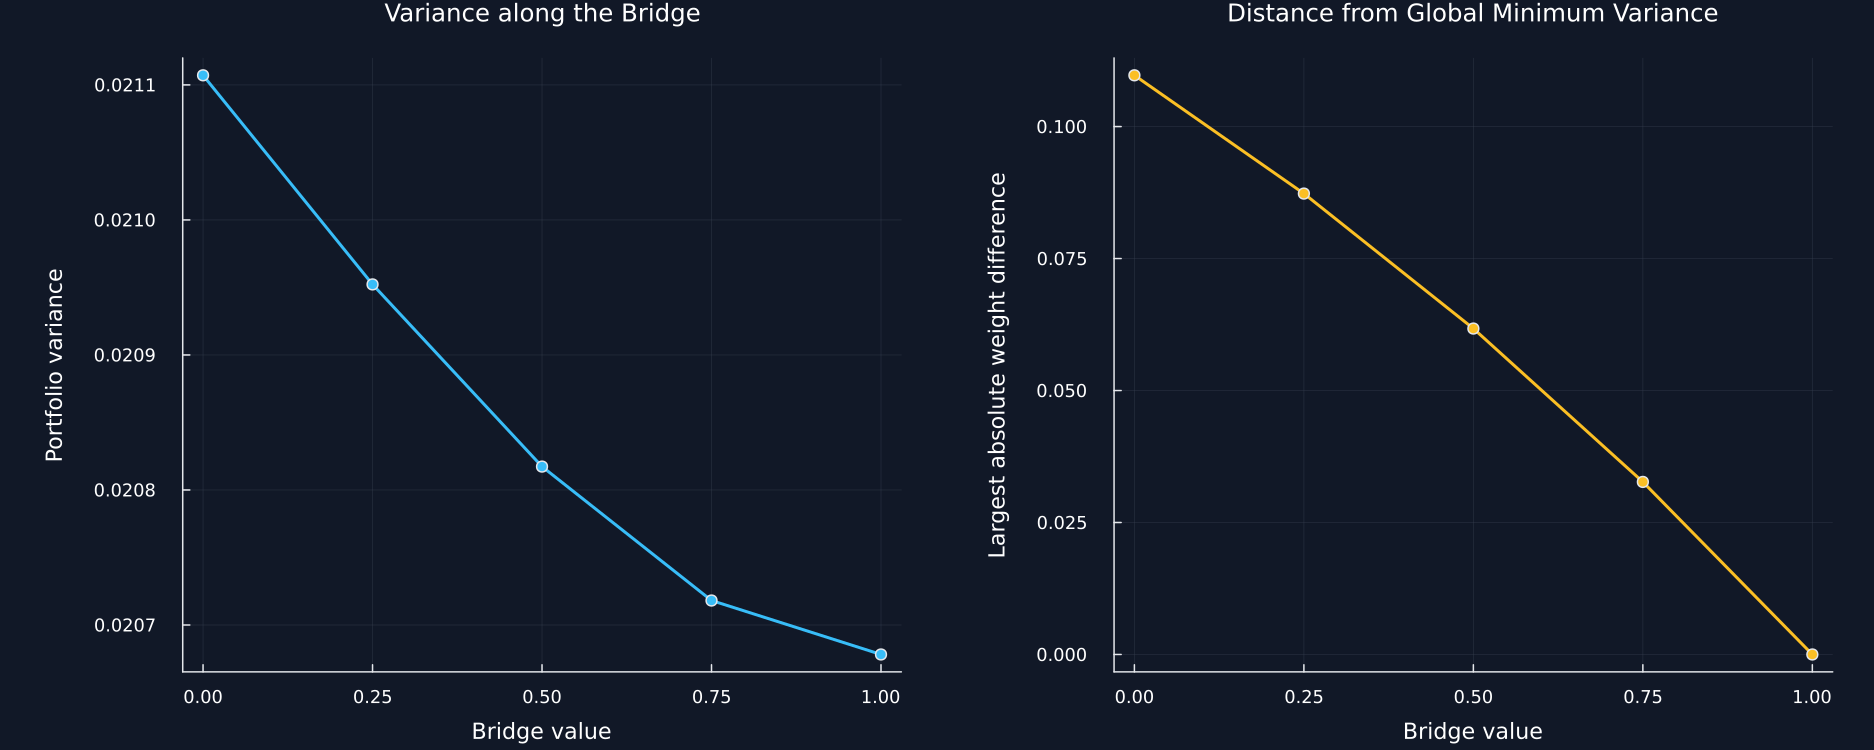

In [5]:
bridge_labels = ["Cluster A knot", "Cluster A member", "Cluster B knot", "Cluster B member"]
bridge_values = [.0400 .0280 .0180 .0108; .0280 .0296 .0126 .00756; .0180 .0126 .0900 .0540; .0108 .00756 .0540 .0474]
bridge_clusters, bridge_knots = [[1, 2], [3, 4]], [1, 3]
bridge_ones = ones(4)
bridge_direction_rows, bridge_adjusted_rows = NamedTuple[], NamedTuple[]
function schur_bridge_weights(gamma; record=false)
    direction_matrix = zeros(4, 2)
    for (cluster_number, members) in enumerate(bridge_clusters)
        other_knots = [knot for (number, knot) in enumerate(bridge_knots) if number != cluster_number]
        cluster_block = bridge_values[members, members]
        cross_block = bridge_values[members, other_knots]
        knot_block = bridge_values[other_knots, other_knots]
        adjusted_covariance = cluster_block - gamma .* (cross_block * (knot_block \ cross_block'))
        adjusted_direction = ones(length(members)) - gamma .* (cross_block * (knot_block \ ones(length(other_knots))))
        direction_matrix[members, cluster_number] = adjusted_covariance \ adjusted_direction
        if record
            append!(bridge_adjusted_rows, [(gamma=gamma, cluster=cluster_number, row=i, column=j, covariance=adjusted_covariance[i, j], direction=adjusted_direction[i]) for i in 1:2 for j in 1:2])
        end
    end
    outer_direction = (direction_matrix' * bridge_values * direction_matrix) \ (direction_matrix' * bridge_ones)
    unscaled = direction_matrix * outer_direction
    if record
        append!(bridge_direction_rows, [(gamma=gamma, row=i, column=j, value=direction_matrix[i, j]) for i in 1:4 for j in 1:2])
    end
    return unscaled / sum(unscaled)
end
bridge_within = zeros(4, 2)
for (cluster_number, members) in enumerate(bridge_clusters)
    bridge_within[members, cluster_number] = optimal_weights(bridge_values[members, members])
end
bridge_reduced = bridge_within' * bridge_values * bridge_within
bridge_between = bridge_reduced \ ones(2)
bridge_between = bridge_between / sum(bridge_between)
prescribed_nco = bridge_within * bridge_between
global_minimum = optimal_weights(bridge_values)
bridge_rows = NamedTuple[]
for gamma in range(0., 1.; length=5)
    weights = schur_bridge_weights(gamma; record=true)
    push!(bridge_rows, (gamma=gamma, a_knot=weights[1], a_member=weights[2], b_knot=weights[3], b_member=weights[4], variance=portfolio_variance(weights, bridge_values), gap=maximum(abs.(weights .- global_minimum))))
end
bridge_example = DataFrame(bridge_rows)
rename!(bridge_example, ["Gamma", "A knot", "A member", "B knot", "B member", "Variance", "Max gap to global minimum"])
publish(bridge_example, "schur_bridge_example", "A two-cluster bridge under the gateway condition.", "tab:chapter22-schur-example")
p1 = plot(bridge_example.Gamma, bridge_example.Variance; marker=:circle, color=palette.cyan, legend=false, title="Variance along the Bridge", xlabel="Bridge value", ylabel="Portfolio variance")
p2 = plot(bridge_example.Gamma, bridge_example[!, "Max gap to global minimum"]; marker=:circle, color=palette.amber, legend=false, title="Distance from Global Minimum Variance", xlabel="Bridge value", ylabel="Largest absolute weight difference")
save_figure(plot(p1, p2; layout=(1, 2), size=(1250, 500), left_margin=12Plots.mm), paths, "schur_bridge_example")
save_data(DataFrame(bridge_values, :auto), paths, "bridge_covariance")
save_data(DataFrame(bridge_within, :auto), paths, "bridge_within")
save_data(DataFrame(bridge_reduced, :auto), paths, "bridge_reduced")
save_data(DataFrame(bridge_direction_rows), paths, "bridge_directions")
save_data(DataFrame(bridge_adjusted_rows), paths, "bridge_adjusted")
save_data(DataFrame(asset=1:4, prescribed_nco=prescribed_nco, global_minimum=global_minimum), paths, "bridge_reference_weights")
nothing


## Controlled Timing Demonstration

This controlled example repeats the same small independent calculation with a fixed $0.03$-second wait. It measures how elapsed time changes when independent calculations are arranged together. It does not measure NCO speed. A measured time ratio compares doing the calculations one at a time with doing $p$ at the same time:

$$
S_p=\frac{t_{1}}{t_p}.
$$

Here, $t_1$ is elapsed time when the calculations are done one at a time, $t_p$ is elapsed time when up to $p$ calculations are done at once, and $S_p$ is a machine-specific timing result rather than a mathematical guarantee.

Row,Execution form,Calculations at once,Independent calculations,Elapsed seconds,One-at-a-time time ratio,Results match
,String,Int64,Int64,Float64,Float64,String
1,One at a time,1,20,0.80537,1.0,Yes
2,Two at a time,2,20,0.817779,0.984826,Yes
3,Two at a time in groups,2,20,0.723665,1.1129,Yes


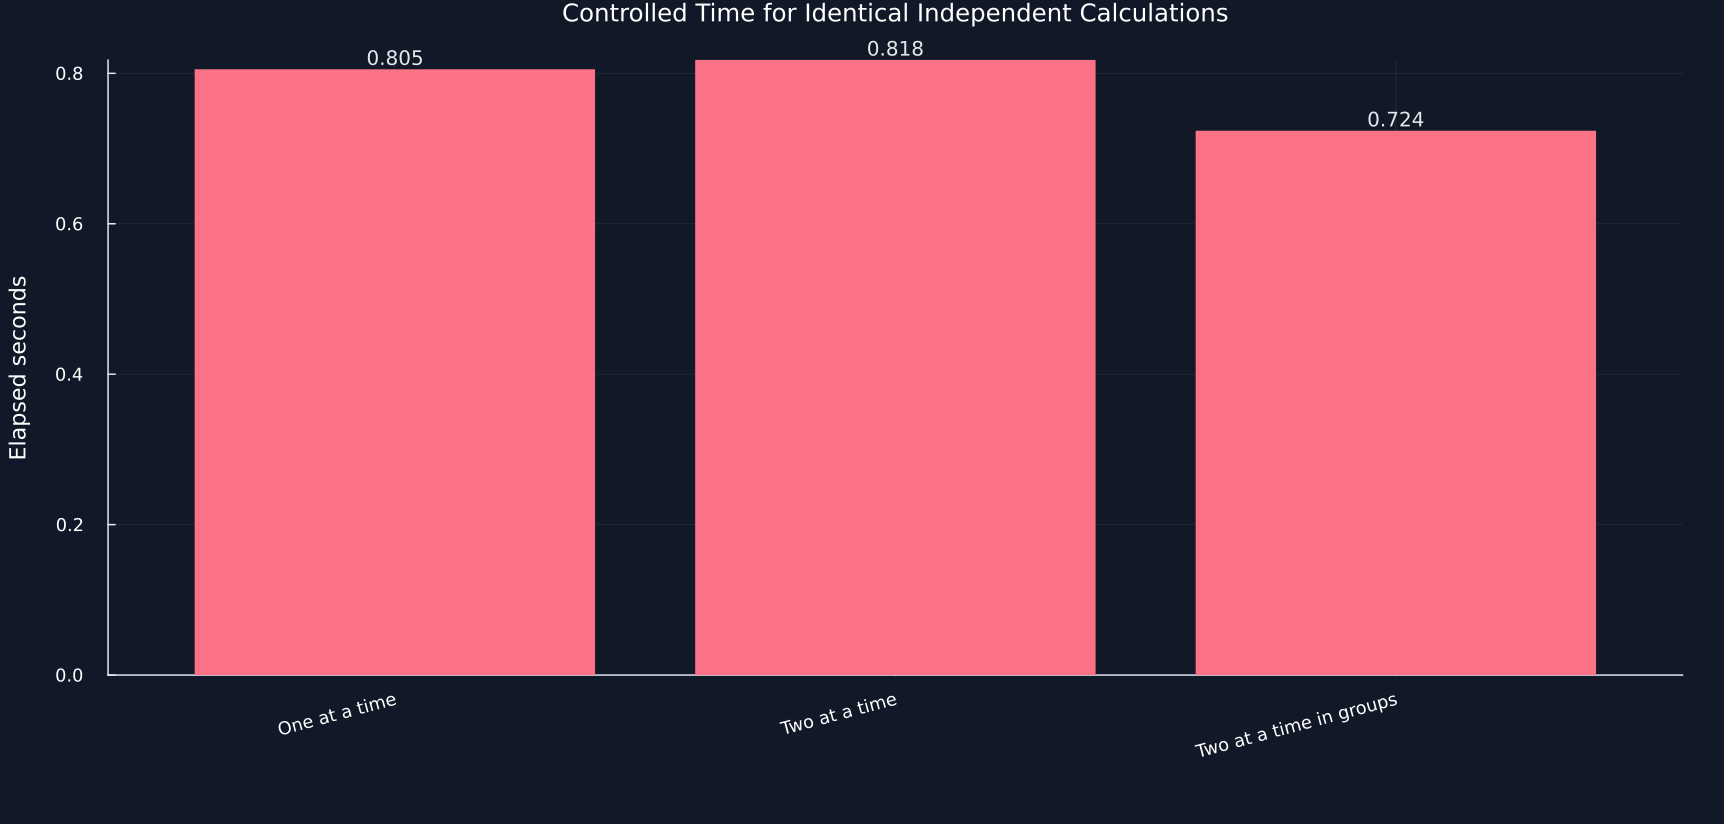

In [6]:
timing_jobs = collect(0:19)
timing_normals = primitive("timing_normals.csv")
function independent_job(job)
    sleep(.03)
    values = view(timing_normals, :, Int(job) + 1)
    return mean(values .^ 2)
end
chunked_jobs(indices) = [independent_job(timing_jobs[Int(index)]) for index in indices]
serial_start = time_ns()
serial_results = [independent_job(job) for job in timing_jobs]
serial_elapsed = (time_ns() - serial_start) / 1e9
item_start = time_ns()
item_results = Float64.(parallel_run(independent_job, timing_jobs; num_cpus=2, lin_partition=false))
item_elapsed = (time_ns() - item_start) / 1e9
chunk_start = time_ns()
chunk_results = Float64.(parallel_run(chunked_jobs, timing_jobs; num_cpus=2, lin_partition=true))
chunk_elapsed = (time_ns() - chunk_start) / 1e9
timing_summary = DataFrame("Execution form" => ["One at a time", "Two at a time", "Two at a time in groups"], "Calculations at once" => [1, 2, 2], "Independent calculations" => fill(length(timing_jobs), 3), "Elapsed seconds" => [serial_elapsed, item_elapsed, chunk_elapsed], "One-at-a-time time ratio" => [1., serial_elapsed / item_elapsed, serial_elapsed / chunk_elapsed], "Results match" => ["Yes", public_allclose(serial_results, item_results) ? "Yes" : "No", public_allclose(serial_results, chunk_results) ? "Yes" : "No"])
publish(timing_summary, "independent_execution_timing", "Measured time and result equality for a controlled independent calculation.", "tab:chapter22-execution-timing")
figure = bar(1:3, timing_summary[!, "Elapsed seconds"]; xticks=(1:3, timing_summary[!, "Execution form"]), xrotation=15, color=[palette.rose palette.cyan palette.green], linealpha=0, legend=false, title="Controlled Time for Identical Independent Calculations", ylabel="Elapsed seconds", size=(1150, 550), bottom_margin=15Plots.mm)
for index in 1:3
    annotate!(figure, index, timing_summary[index, "Elapsed seconds"], text(@sprintf("%.3f", timing_summary[index, "Elapsed seconds"]), 9, palette.text, :bottom))
end
save_figure(figure, paths, "serial_parallel_execution")
save_data(DataFrame(job=timing_jobs, serial=serial_results, item=item_results, chunk=chunk_results), paths, "timing_results")
save_data(DataFrame(default_threads=[Threads.nthreads()], requested_workers=[2], delay_seconds=[.03], independent_jobs=[20], observations_per_job=[2000], item_result_count=[length(item_results)], chunk_result_count=[length(chunk_results)]), paths, "timing_runtime")
nothing


## Chronological Public Comparison

Held-out volatility and one-way turnover measure different parts of a rolling allocation:

$$
\widehat\sigma_{k,m}^{\mathrm{test}}=\sqrt{252}\,\operatorname{sd}(R_k^{\mathrm{test}}w_{k,m}),
\qquad
\operatorname{TO}_{k,m}=\frac{1}{2}\lVert w_{k,m}-w_{k-1,m}\rVert_1.
$$

Here, $k$ labels a chronological window, $m$ labels a portfolio rule, $R_k^{\mathrm{test}}$ is the held-out return matrix, $w_{k,m}$ is fitted on earlier observations, and $\operatorname{sd}$ is sample standard deviation. The factor $252$ is the assumed number of trading days in one year. The notation $\lVert x\rVert_1$ means the sum of the absolute entries of $x$. Dividing by two counts the matching sale and purchase sides of one rebalance once. The turnover measure $\operatorname{TO}_{k,m}$ excludes trading costs.

Row,Quantity,Value
,String,String
1,Assets,16
2,Training observations,252
3,Held-out observations,63
4,Window step,126
5,Windows,12
6,Portfolio rules,5
7,Trading costs included,No


Row,Method,Mean held-out volatility,Mean one-way turnover,Mean gross exposure,Lowest-volatility folds
,String,Float64,Float64,Float64,Int64
1,Equal weight,0.175816,0.0,1.0,0
2,HRP,0.158888,0.0865544,1.0,1
3,Inverse variance,0.158456,0.0620561,1.0,3
4,NCO,0.15577,0.589027,1.69969,2
5,Ordinary minimum variance,0.155934,0.668246,1.97073,6


Row,Preliminary experiment,Chapter 22 location,Status
,String,String,String
1,Block-correlation condition numbers,Section 22.1,Included
2,Public covariance cleaning and clustering,Sections 22.1 and 22.2,Included
3,Within-cluster optimization,Section 22.1,Included
4,Reduced cluster covariance,Section 22.1,Included
5,Between-cluster optimization,Section 22.1,Included
6,Direct library NCO call,Section 22.1,Included
7,Own-decision allocation error,Section 22.2,Included
8,Error to the ordinary population optimum,Section 22.2,Included
9,Maximum-Sharpe allocation error,Section 22.2,Included


Row,Quantity,Value
,String,Int64
1,Known-input objectives,2
2,Independent repeated samples,80
3,Sensitivity method results,120
4,Public rolling windows,12
5,Compared public rules,5
6,Public observations,1760


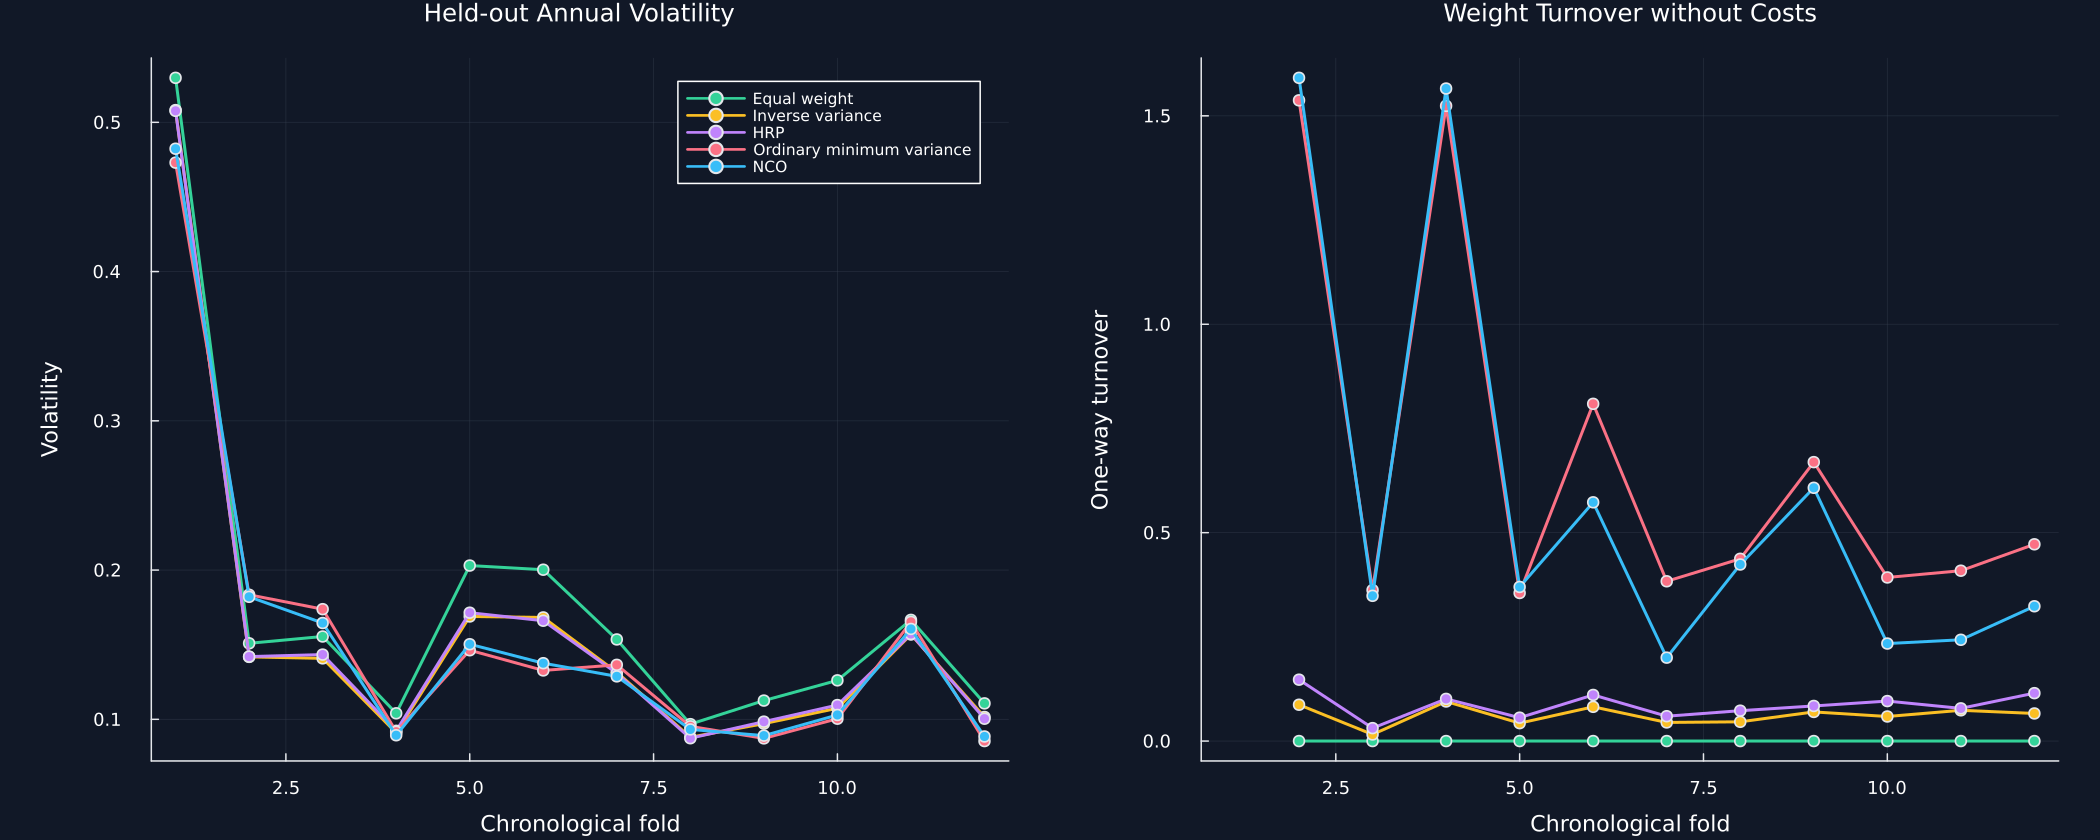

In [7]:
rolling_rows = NamedTuple[]
previous_weights = Dict{String,Vector{Float64}}()
fold = 0
public_method_order = ["Equal weight", "Inverse variance", "HRP", "Ordinary minimum variance", "NCO"]
for training_end in 252:126:size(public_sample, 1)-63
    training = public_sample[training_end-251:training_end, :]
    testing = public_sample[training_end+1:training_end+63, :]
    covariance = cov(training) * 252
    fold += 1
    portfolios = five_portfolios("public_" * string(fold), covariance, 2250)
    for (method, weights) in portfolios
        held_out = testing * weights
        turnover = haskey(previous_weights, method) ? .5sum(abs, weights .- previous_weights[method]) : NaN
        push!(rolling_rows, (fold=fold, training_end=string(dates[training_end]), test_end=string(dates[training_end+63]), method=method, volatility=std(held_out) * sqrt(252), turnover=turnover, gross=sum(abs, weights), concentration=dot(weights, weights)))
        previous_weights[method] = copy(weights)
    end
end
public_rolling = DataFrame(rolling_rows)
rename!(public_rolling, ["Fold", "Training end", "Test end", "Method", "Held-out annual volatility", "One-way turnover", "Gross exposure", "Weight concentration"])
rolling_summary = combine(groupby(public_rolling, "Method"; sort=true), "Held-out annual volatility" => mean => "Mean held-out volatility", "Held-out annual volatility" => median => "Median held-out volatility", "One-way turnover" => finite_mean => "Mean one-way turnover", "Gross exposure" => mean => "Mean gross exposure", "Weight concentration" => median => "Median weight concentration")
rolling_winners = Dict(method => 0 for method in public_method_order)
for window in 1:fold
    subset = public_rolling[public_rolling.Fold .== window, :]
    rolling_winners[subset[argmin(subset[!, "Held-out annual volatility"]), "Method"]] += 1
end
rolling_summary[!, "Lowest-volatility folds"] = [rolling_winners[method] for method in rolling_summary.Method]
rolling_design = DataFrame("Quantity" => ["Assets", "Training observations", "Held-out observations", "Window step", "Windows", "Portfolio rules", "Trading costs included"], "Value" => string.([16, 252, 63, 126, fold, 5, "No"]))
preliminary_parity = DataFrame("Preliminary experiment" => ["Block-correlation condition numbers", "Public covariance cleaning and clustering", "Within-cluster optimization", "Reduced cluster covariance", "Between-cluster optimization", "Direct library NCO call", "Own-decision allocation error", "Error to the ordinary population optimum", "Maximum-Sharpe allocation error", "Five-rule raw and denoised comparison", "One-at-a-time and grouped execution"], "Chapter 22 location" => ["Section 22.1", "Sections 22.1 and 22.2", "Section 22.1", "Section 22.1", "Section 22.1", "Section 22.1", "Section 22.2", "Section 22.2", "Section 22.2", "Section 22.2", "Section 22.2"], "Status" => fill("Included", 11))
section_summary = DataFrame("Quantity" => ["Known-input objectives", "Independent repeated samples", "Sensitivity method results", "Public rolling windows", "Compared public rules", "Public observations"], "Value" => [2, 80, nrow(sensitivity_results), fold, 5, size(public_sample, 1)])
rolling_book_summary = rolling_summary[:, ["Method", "Mean held-out volatility", "Mean one-way turnover", "Mean gross exposure", "Lowest-volatility folds"]]
publish(rolling_design, "public_nco_rolling_design", "Chronological public NCO comparison design.", "tab:chapter22-public-rolling-design")
publish(rolling_book_summary, "public_nco_rolling_summary", "Held-out public risk, turnover, and exposure summaries.", "tab:chapter22-public-rolling-summary")
publish(preliminary_parity, "preliminary_nco_parity", "Coverage of preliminary NCO and execution experiments.", "tab:chapter22-preliminary-parity")
publish(section_summary, "estimation_error_section_summary", "Section 22.2 numerical summary.", "tab:chapter22-estimation-section-summary")
p1 = plot(; title="Held-out Annual Volatility", xlabel="Chronological fold", ylabel="Volatility", legendfontsize=7)
p2 = plot(; title="Weight Turnover without Costs", xlabel="Chronological fold", ylabel="One-way turnover", legend=false)
for (method, color) in zip(public_method_order, [palette.green, palette.amber, violet, palette.rose, palette.cyan])
    subset = public_rolling[public_rolling.Method .== method, :]
    plot!(p1, subset.Fold, subset[!, "Held-out annual volatility"]; color, marker=:circle, label=method)
    plot!(p2, subset.Fold, subset[!, "One-way turnover"]; color, marker=:circle, label=method)
end
save_figure(plot(p1, p2; layout=(1, 2), size=(1400, 560), left_margin=12Plots.mm), paths, "public_nco_rolling_comparison")
save_data(public_rolling, paths, "public_rolling")
save_data(rolling_summary, paths, "rolling_summary")
nothing


## Tests

In [8]:
@assert size(public_sample) == (1760, 16)
@assert size(true_covariance) == (24, 24)
@assert minimum(eigvals(Symmetric(true_covariance))) > 0
@assert public_allclose(diag(true_correlation), 1.)
@assert nrow(mcos_results) == 2 * 40 * 2
@assert all(combine(groupby(mcos_results, ["Objective", "Repetition"]), nrow => :count).count .== 2)
@assert all(mcos_results[!, "Own-decision allocation error"] .>= 0)
@assert all(mcos_results[!, "Error to ordinary population optimum"] .>= 0)
@assert all(mcos_results[!, "True variance"] .> 0)
@assert nrow(mcos_summary) == 4
@assert nrow(error_ratios) == 2
@assert all(error_ratios[!, "NCO error as percent of ordinary error"] .> 0)
@assert paper_design_results[!, "Raw NCO error as percent of ordinary error"] == [44.95, 42.2]
@assert minimum(eigvals(Symmetric(demonstration_denoised))) > 0
@assert Set(denoising_summary.Method) == Set(["Equal weight", "Inverse variance", "HRP", "Ordinary minimum variance", "NCO"])
@assert nrow(denoising_summary) == 10
@assert all(denoising_comparison[!, "Raw known variance"] .> 0)
@assert all(denoising_comparison[!, "Denoised known variance"] .> 0)
@assert nrow(sensitivity_results) == 2 * 3 * 10 * 2
@assert all(combine(groupby(sensitivity_results, ["Within-cluster correlation", "Training observations", "Repetition"]), nrow => :count).count .== 2)
@assert all(sensitivity_results[!, "True-risk ratio"] .>= 1 - 1e-9)
@assert nrow(sensitivity_summary) == 2 * 3 * 2
@assert public_allclose(serial_results, item_results)
@assert public_allclose(serial_results, chunk_results)
@assert all(timing_summary[!, "Results match"] .== "Yes")
@assert all(timing_summary[!, "Elapsed seconds"] .> 0)
@assert public_allclose(schur_bridge_weights(0.), prescribed_nco)
@assert public_allclose(schur_bridge_weights(1.), global_minimum)
@assert public_allclose(bridge_values[2, [3, 4]] .- .7 .* bridge_values[1, [3, 4]], 0.)
@assert public_allclose(bridge_values[4, [1, 2]] .- .6 .* bridge_values[3, [1, 2]], 0.)
@assert all(bridge_example.Variance .> 0)
@assert all(combine(groupby(public_rolling, "Fold"), nrow => :count).count .== 5)
@assert sum(rolling_summary[!, "Lowest-volatility folds"]) == fold
@assert all(rolling_summary[!, "Mean held-out volatility"] .> 0)
@assert all(rolling_summary[!, "Mean one-way turnover"] .>= 0)
@assert nrow(preliminary_parity) == 11
@assert all(preliminary_parity.Status .== "Included")
@assert nrow(section_summary) == 6
@assert isfile(joinpath(paths.figures, "known_and_estimated_nco_correlation.pdf"))
@assert isfile(joinpath(paths.figures, "mcos_allocation_error.pdf"))
@assert isfile(joinpath(paths.figures, "denoising_correlation_comparison.pdf"))
@assert isfile(joinpath(paths.figures, "denoising_true_risk_comparison.pdf"))
@assert isfile(joinpath(paths.figures, "nco_sampling_sensitivity.pdf"))
@assert isfile(joinpath(paths.figures, "schur_bridge_example.pdf"))
@assert isfile(joinpath(paths.figures, "serial_parallel_execution.pdf"))
@assert isfile(joinpath(paths.figures, "public_nco_rolling_comparison.pdf"))
@assert isfile(joinpath(paths.tables, "mcos_nco_summary.tex"))
@assert isfile(joinpath(paths.tables, "public_nco_rolling_summary.tex"))
save_data(DataFrame(candidate_rows), paths, "candidate_fits")
save_data(DataFrame(cluster_rows), paths, "selected_clusters")
save_data(DataFrame(weight_rows), paths, "portfolio_weights")
save_data(DataFrame(sample_rows), paths, "samples")
save_data(DataFrame(covariance_rows), paths, "case_covariances")
save_data(DataFrame(batch=1:length(case_order), case=case_order), paths, "case_order")
println("All complete Chapter 26.02 assertions passed, including the Schur bridge and all three execution forms.")


All complete Chapter 26.02 assertions passed, including the Schur bridge and all three execution forms.
